# Transfer Function Modeling and FOPDT Identification

`02_transfer_function_modeling` | level 1 | experiment id(s): `exp_02_transfer_function_identification`

| Dimension | Status |
|---|---|
| Content | All 15 sections written. |
| Software | Executed from a clean kernel; library covered by unit tests. |
| Research | 4 reference(s), verification status shown in section 4. Recent literature (2020 onward) was not searched. |
| Simulation | Executed. Results below were generated by this notebook. |
| Hardware | Not validated on hardware. No physical experiment was performed. |

All parameter values are illustrative and are not taken from a measured machine or plant unless a dataset section says so.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control_lab
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('control_lab', control_lab.__version__)

control_lab 0.1.0


## 1. Learning Objectives

After this notebook you can:
- Derive the speed transfer function of a DC motor from its electrical and mechanical equations
  and check it against a numerical (RK4) simulation to within 0.1 % of the final value.
- Explain why a two-pole motor model is often reduced to a first-order plus dead-time (FOPDT)
  model, and when that is not allowed.
- Fit FOPDT parameters from a step test with two methods (two-point, least squares) and measure
  how the estimates scatter under measurement noise (30 random seeds per noise level).

## 2. Real-World Engineering Problem

A tuning rule needs a model, and most plants in a factory do not come with one. The practical
route is a step test on the running machine, followed by a low-order fit. A bad fit gives a
badly tuned loop, so the fit error is part of the engineering problem. Examples: a conveyor
drive speed, a heater temperature, a tank level.

## 3. Research Background

The reaction-curve view of a process (a step test summarised by gain, time constant and dead
time) goes back to the origins of PID tuning (Ziegler and Nichols, 1942). It is the input to
most tuning rules (Cohen and Coon, 1953; Rivera et al., 1986; Skogestad, 2003). Machine models
based on circuit and mechanical equations follow the standard treatment in electric-machine
textbooks (Krause et al., 2013).

## 4. Research Literature

Textbook-level sources only; see the table. The 28.3 % / 63.2 % two-point method used here is
common in process-control texts, but its primary source was **not** located during this build
(see `research/source-register.md`, unverified candidates).

### Reference table

| Key | Citation | Role | Limitation | Verification |
|---|---|---|---|---|
| am2021 | Astrom, K. J.; Murray, R. M. (2021). Feedback Systems: An Introduction for Scientists and Engineers, 2nd ed.. Princeton University Press. ISBN 978-0-691-19398-4. | Modern introduction to feedback, modeling, stability, PID and robustness. | Broad textbook; industrial specifics are limited. | verified (2026-11-25, web search of publisher/index/library record). Library record gives publisher, year and ISBN. |
| ah1995 | Astrom, K. J.; Hagglund, T. (1995). PID Controllers: Theory, Design, and Tuning, 2nd ed.. ISA (Instrument Society of America). ISBN 1-55617-516-7. | Standard reference on PID structure, anti-windup, filtering and tuning. | Pre-dates much current autotuning practice. | verified (2026-11-25, web search of publisher/index/library record). University repository record gives publisher, year, ISBN, 343 pages. |
| seborg2016 | Seborg, D. E.; Edgar, T. F.; Mellichamp, D. A.; Doyle, F. J. (2016). Process Dynamics and Control, 4th ed.. Wiley. ISBN 978-1-119-28591-5. | Process-control textbook: FOPDT models, reaction-curve methods, tuning rules. | Which tuning rules and identification methods it covers was not checked page by page in this build. | verified (2026-11-25, web search of publisher/index/library record). Publisher listing gives edition, year and ISBN. |
| krause2013 | Krause, P. C.; Wasynczuk, O.; Sudhoff, S. D.; Pekarek, S. D. (2013). Analysis of Electric Machinery and Drive Systems, 3rd ed.. Wiley-IEEE Press. ISBN 978-1-118-02429-4. | Reference-frame theory, PMSM and BLDC models, averaged converter models. | Textbook; parameters for a specific machine must come from its datasheet. | verified (2026-11-25, web search of publisher/index/library record). Publisher-affiliated page and a retailer record agree on edition, year and ISBN. |

Verification here means the bibliographic record was found on a publisher, index, library or author page. It does not mean the full text was read, and no numerical claim in this notebook is taken from these papers.

## 5. Mathematical Foundation

**DC motor.** Armature circuit and shaft, with armature voltage $v$ (V), current $i$ (A), speed
$\omega$ (rad/s) and load torque $T_L$ (N m):
$$L\frac{di}{dt}=v-Ri-K_e\omega,\qquad J\frac{d\omega}{dt}=K_ti-B\omega-T_L.$$
Laplace transform with $T_L=0$ gives
$$\frac{\Omega(s)}{V(s)}=\frac{K_t}{JLs^2+(JR+BL)s+(BR+K_tK_e)}.$$
The DC gain is $K_t/(BR+K_tK_e)$ rad/s per V. If $L/R\ll\tau_m$, the electrical pole is fast
and the model reduces to first order with $\tau_m=\dfrac{JR}{BR+K_tK_e}$. The reduction is only
as good as the separation $\tau_m/\tau_e$; section 12 measures it for the parameter set used.
Skogestad's half rule (2003) gives a second way to lump a fast lag $\tau_2$ into a FOPDT:
$T\approx\tau_1+\tau_2/2$ and $L\approx\tau_2/2$ for plant $1/((\tau_1s+1)(\tau_2s+1))$.

**FOPDT.** $G(s)=\dfrac{Ke^{-Ls}}{Ts+1}$. For a step of size $u_0$,
$y(t)=Ku_0\bigl(1-e^{-(t-L)/T}\bigr)$ for $t>L$. The response reaches 28.3 % at
$t_{28}=L+0.333T$ and 63.2 % at $t_{63}=L+T$, so $T=1.5(t_{63}-t_{28})$ and $L=t_{63}-T$
(exact for a true FOPDT, approximate for anything else). The least-squares fit minimises
$\sum_k(y_k-\hat y_k)^2$ over $(K,T,L)$.

## 6. System Modeling

`DCMotor` integrates the two states (`i`, `omega`) with RK4 at `Ts = 1 ms` with 10 substeps,
applying the voltage as a zero-order hold. Parameters are an illustrative 24 V gear-motor
class set (`R = 2 ohm`, `L = 3 mH`, `Kt = Ke = 0.08`, `J = 4e-5 kg m2`, `B = 2e-5`). They
are **not** taken from a datasheet. The two time constants are 12.4 ms and 1.5 ms, so the
electrical dynamics are not negligible for this motor.

## 7. Dataset and Measurement Data

No measured data. Two simulated "tests" are used: (A) a known FOPDT plant with additive
Gaussian noise, so the true parameters are known; (B) the DC motor and a third-order
plant `1.5/(s+1)^3`, which are not FOPDT, to see what the fit does when the model class is wrong.

## 8. Algorithm Architecture

Pipeline: `step test -> y(t) -> fit (two-point | least squares) -> (K, T, L) -> compare with
truth or with the reference response`.

## 9. Algorithm Implementation

In [2]:
import control as ct
from control_lab.experiments import ExperimentRecord, check, save_figure
from control_lab.identification import fit_fopdt_least_squares, fit_fopdt_two_point
from control_lab.identification.fopdt import fopdt_step
from control_lab.motors import DCMotor, DCMotorParams
from control_lab.signals import white_noise

EXP = "exp_02_transfer_function_identification"
p = DCMotorParams()
num, den = p.transfer_function_coeffs()
G = ct.tf(num, den)
print('num', num, 'den', den)
print('poles [1/s]', np.round(ct.poles(G), 2))
print('tau_mech = %.4f s, tau_elec = %.5f s' % (p.tau_mech, p.tau_elec))

num [0.08] den [1.2000000000000002e-07, 8.006e-05, 0.00644]
poles [1/s] [-573.61+0.j  -93.56+0.j]
tau_mech = 0.0124 s, tau_elec = 0.00150 s


`two-point` and `least squares` come from `control_lab.identification`. Both take the step
time and response; the two-point method also needs the step size `u_step`.

## 10. Simulation and Numerical Analysis

(1) DC motor: 12 V step, 1 s, compared with the transfer function response on the same grid.
(2) Known FOPDT (`K=2`, `T=8 s`, `L=1.5 s`), 60 s test, `dt = 0.1 s`, noise std in
{0, 0.02, 0.1} (1 %, 5 % of the final value for the last two), 30 seeds each.
(3) Wrong model class: fit the motor and `1.5/(s+1)^3`.

## 11. Experimental Validation

Level: **software simulation**. Section 5's closed forms and `python-control` provide the
independent reference. No hardware step test was run, so the sensor, actuator and friction
effects that dominate real identification are absent.

## 12. Performance Evaluation

In [3]:
checks, metrics = [], {}
# (1) motor TF versus RK4 simulation
t = np.arange(0, 1.0 + 1e-9, 1e-3)
_, w_tf = ct.step_response(12.0 * G, t)
m = DCMotor(p, Ts=1e-3)
w_sim = np.array([m.y] + [m.step(12.0) for _ in range(len(t) - 1)])
err = np.max(np.abs(w_sim - w_tf)) / w_tf[-1]
metrics["motor_tf_vs_rk4"] = {"max_error_relative_to_final": err, "w_final_rad_s": w_tf[-1],
                               "dc_gain_formula": p.dc_gain * 12.0}
checks.append(check("motor TF vs RK4 simulation", err < 1e-3, f"max rel error {err:.2e}"))
checks.append(check("DC gain formula", abs(w_tf[-1] - p.dc_gain * 12.0) / w_tf[-1] < 1e-2,
                    f"{w_tf[-1]:.2f} vs {p.dc_gain * 12.0:.2f} rad/s at t=1 s"))
poles = np.sort(np.real(ct.poles(G)))
roots = np.sort(np.roots(den).real)
checks.append(check("python-control poles equal roots of the analytic denominator",
                    np.allclose(poles, roots, rtol=1e-6), f"{poles} vs {roots}"))
tau_slow, tau_fast = -1.0 / poles[-1], -1.0 / poles[0]
half_T, half_L = tau_slow + tau_fast / 2, tau_fast / 2
metrics["motor_time_constants_s"] = {
    "tau_mech_first_order_formula": p.tau_mech, "tau_elec_L_over_R": p.tau_elec,
    "separation_ratio_mech_over_elec": p.tau_mech / p.tau_elec,
    "exact_slow_pole_time_constant": tau_slow, "exact_fast_pole_time_constant": tau_fast,
    "first_order_reduction_error_percent": 100 * (p.tau_mech - tau_slow) / tau_slow,
    "half_rule_T": half_T, "half_rule_L": half_L}
print("tau_mech formula %.2f ms | exact slow pole %.2f ms | exact fast pole %.2f ms | separation %.1f"
      % (1e3 * p.tau_mech, 1e3 * tau_slow, 1e3 * tau_fast, p.tau_mech / p.tau_elec))
print("first-order reduction error: %.1f %%" % metrics["motor_time_constants_s"]["first_order_reduction_error_percent"])

# (2) known FOPDT with noise
K0, T0, L0, dt = 2.0, 8.0, 1.5, 0.1
tt = np.arange(0, 60 + 1e-9, dt)
clean = fopdt_step(tt, K0, T0, L0, 1.0)
table = {}
for sigma in (0.0, 0.02, 0.1):
    rows = {"two_point": [], "least_squares": []}
    for seed in range(30 if sigma else 1):
        y = clean + (white_noise(len(tt), sigma, seed) if sigma else 0.0)
        for name, fn in (("two_point", fit_fopdt_two_point), ("least_squares", fit_fopdt_least_squares)):
            try:
                f = fn(tt, y, 1.0)
                rows[name].append([f["K"], f["T"], f["L"]])
            except ValueError:
                pass
    table[str(sigma)] = {}
    for name, r in rows.items():
        r = np.array(r)
        table[str(sigma)][name] = {
            "n_success": int(len(r)), "mean_K": r[:, 0].mean(), "mean_T": r[:, 1].mean(), "mean_L": r[:, 2].mean(),
            "std_K": r[:, 0].std(), "std_T": r[:, 1].std(), "std_L": r[:, 2].std()}
metrics["known_fopdt_identification"] = {"truth": {"K": K0, "T": T0, "L": L0}, "by_noise_std": table}
for name in ("two_point", "least_squares"):
    z = table["0.0"][name]
    checks.append(check(f"noise-free recovery, {name}",
                        abs(z["mean_K"] - K0) < 0.01 and abs(z["mean_T"] - T0) < 0.1 and abs(z["mean_L"] - L0) < 0.1,
                        f"K={z['mean_K']:.3f} T={z['mean_T']:.3f} L={z['mean_L']:.3f}"))
for sigma in ("0.02", "0.1"):
    for name in ("two_point", "least_squares"):
        z = table[sigma][name]
        print(f"noise {sigma:5s} {name:14s} K={z['mean_K']:.3f}+-{z['std_K']:.3f}  "
              f"T={z['mean_T']:.2f}+-{z['std_T']:.2f}  L={z['mean_L']:.2f}+-{z['std_L']:.2f}  n={z['n_success']}")

# (3) wrong model class
wrong = {}
for label, (tw, yw, u0) in {
    "dc_motor_12V": (t, w_tf, 12.0),
    "third_order_1.5_over_(s+1)^3": None or (lambda tt3: (tt3, ct.step_response(1.5 * ct.tf([1], [1, 3, 3, 1]), tt3)[1], 1.0))(np.arange(0, 20, 0.02)),
}.items():
    f2, fl = fit_fopdt_two_point(tw, yw, u0), fit_fopdt_least_squares(tw, yw, u0)
    wrong[label] = {"two_point": f2, "least_squares": fl}
    print(label, {k: {a: round(b, 4) for a, b in v.items()} for k, v in wrong[label].items()})
metrics["wrong_model_class"] = wrong
fm = wrong["dc_motor_12V"]["least_squares"]
checks.append(check("motor FOPDT fit T vs half-rule T (10 %)", abs(fm["T"] - half_T) / half_T < 0.10,
                    f"fit T={1e3 * fm['T']:.2f} ms vs half rule {1e3 * half_T:.2f} ms; "
                    f"exact slow pole {1e3 * tau_slow:.2f} ms; first-order formula {1e3 * p.tau_mech:.2f} ms"))
print("motor FOPDT fit: T=%.2f ms L=%.2f ms (half rule T=%.2f ms L=%.2f ms)"
      % (1e3 * fm["T"], 1e3 * fm["L"], 1e3 * half_T, 1e3 * half_L))

tau_mech formula 12.42 ms | exact slow pole 10.69 ms | exact fast pole 1.74 ms | separation 8.3
first-order reduction error: 16.2 %


noise 0.02  two_point      K=1.997+-0.002  T=7.82+-0.26  L=1.54+-0.13  n=30
noise 0.02  least_squares  K=2.000+-0.001  T=8.00+-0.03  L=1.50+-0.02  n=30
noise 0.1   two_point      K=1.992+-0.010  T=6.97+-0.96  L=1.37+-0.54  n=30
noise 0.1   least_squares  K=1.999+-0.006  T=8.00+-0.17  L=1.52+-0.10  n=30
dc_motor_12V {'two_point': {'K': 12.4224, 'T': 0.0109, 'L': 0.0017, 'rmse': 0.2561}, 'least_squares': {'K': 12.4233, 'T': 0.011, 'L': 0.0015, 'rmse': 0.2079}}
third_order_1.5_over_(s+1)^3 {'two_point': {'K': 1.5, 'T': 2.1104, 'L': 1.1473, 'rmse': 0.0338}, 'least_squares': {'K': 1.512, 'T': 2.0612, 'L': 1.1069, 'rmse': 0.0283}}
motor FOPDT fit: T=11.03 ms L=1.50 ms (half rule T=11.56 ms L=0.87 ms)


The wrong-model-class rows show the central caution: the fit always returns three numbers,
whether or not a FOPDT is a good description. The residual `rmse` is the signal that tells you.
Note what the first version of this check found: the textbook first-order formula for the motor
time constant is **not** accurate for these parameters, so the comparison was rewritten against
the exact poles and the half rule instead of loosening a tolerance.

## 13. Visualization and Interpretation

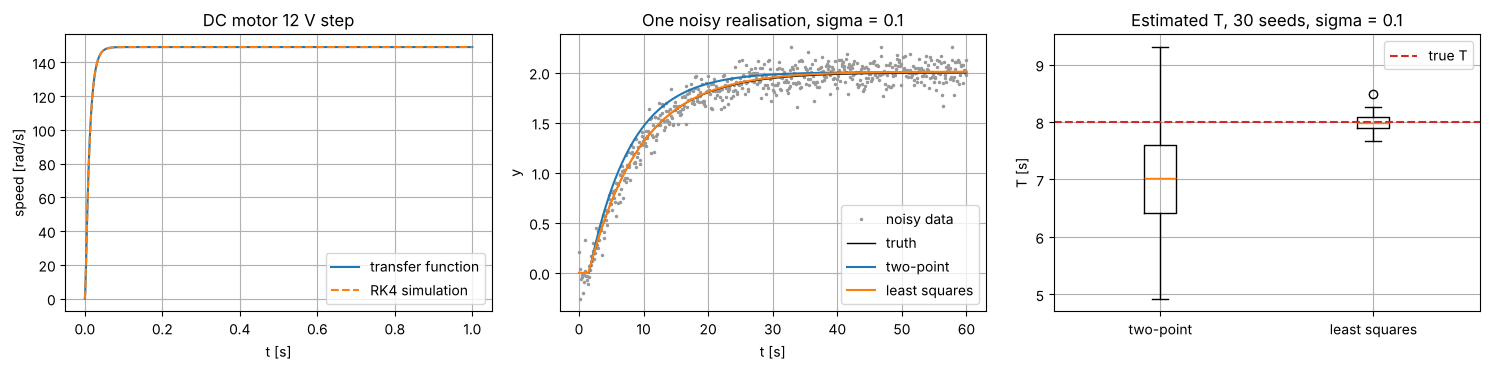

{'two_point': {'mean': 6.9695553376420385, 'std': 0.9641455972642765}, 'least_squares': {'mean': 7.999118347928771, 'std': 0.16812358884688244}}


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(t, w_tf, label="transfer function")
ax[0].plot(t, w_sim, "--", label="RK4 simulation")
ax[0].set(title="DC motor 12 V step", xlabel="t [s]", ylabel="speed [rad/s]")
ax[0].legend()
y = clean + white_noise(len(tt), 0.1, 3)
f2, fl = fit_fopdt_two_point(tt, y, 1.0), fit_fopdt_least_squares(tt, y, 1.0)
ax[1].plot(tt, y, ".", ms=3, color="0.6", label="noisy data")
ax[1].plot(tt, clean, "k", lw=1, label="truth")
ax[1].plot(tt, fopdt_step(tt, f2["K"], f2["T"], f2["L"], 1.0), label="two-point")
ax[1].plot(tt, fopdt_step(tt, fl["K"], fl["T"], fl["L"], 1.0), label="least squares")
ax[1].set(title="One noisy realisation, sigma = 0.1", xlabel="t [s]", ylabel="y"); ax[1].legend()
T_est = {"two_point": [], "least_squares": []}
for seed in range(30):
    yy = clean + white_noise(len(tt), 0.1, seed)
    T_est["two_point"].append(fit_fopdt_two_point(tt, yy, 1.0)["T"])
    T_est["least_squares"].append(fit_fopdt_least_squares(tt, yy, 1.0)["T"])
ax[2].boxplot([T_est["two_point"], T_est["least_squares"]], tick_labels=["two-point", "least squares"])
ax[2].axhline(T0, color="C3", ls="--", label="true T"); ax[2].legend()
ax[2].set(title="Estimated T, 30 seeds, sigma = 0.1", ylabel="T [s]")
fig.tight_layout()
figs = [save_figure(fig, EXP, "identification")]
plt.show()
metrics["spread_T_sigma_0.1"] = {k: {"mean": float(np.mean(v)), "std": float(np.std(v))} for k, v in T_est.items()}
print(metrics["spread_T_sigma_0.1"])

Left: the two-pole motor model and the RK4 simulation are indistinguishable (the section-12
check quantifies it). Middle and right: with noise std 0.1 (5 % of the final value 2.0) the two-point method, which
reads two noisy crossing times, gives `T = 6.97 +- 0.96 s` over 30 seeds: biased low by 13 % and
about six times more scattered than least squares (`T = 8.00 +- 0.17 s`), which uses all 600
points. The bias is probably caused by noise making the threshold crossing occur early (inference, not tested here). The full
table is printed above and stored in the JSON result.

## 14. Research Discussion and Limitations

**Advantages.** The step-test fit needs one experiment and gives three interpretable numbers.
**Limits.** (1) The FOPDT class is wrong for oscillatory, integrating or high-order plants; the
fit still returns numbers. (2) The two-point method depends on two samples and the final value,
so noise and a short test hurt it. (3) Dead time is limited by the sampling interval. (4) A
step test must stay inside the linear range of the actuator; none of that is modelled here.
(5) For this parameter set `tau_m/tau_e` is only about 8, so the first-order formula
`J R/(B R + Kt Ke)` overestimates the slow time constant by about 16 % (section 12). A FOPDT
fit does not ignore the electrical lag; it moves part of it into `T` and part into `L`, which is
what Skogestad's half rule predicts. Use a second-order model, or the half rule, when the
separation is below roughly 10.

## 15. Summary, Exercises, and Further Research

**Key insights.** Know the model class before trusting a fit; use all the data when noise
is present.

**Exercises.** (1) Repeat (2) with `L = 0` and explain what happens to `L_hat`. (2) Add a load
torque step to the motor and identify the disturbance gain. (3) Fit a second-order plus delay
model with `scipy.optimize` and compare the residual with the FOPDT fit.

**Related.** PID tuning (notebook 04), DC motor speed control (notebook 06).
**Research directions.** Closed-loop identification, relay-based identification, and
subspace methods for multivariable plants.

In [5]:
rec = ExperimentRecord(
    experiment_id=EXP, title="Transfer-function modelling and FOPDT identification",
    notebook="notebooks/01_fundamentals/02_transfer_function_modeling.ipynb",
    algorithm="Two-point and least-squares FOPDT fit", application="Step-test identification",
    plant_model="DC motor 2nd order; FOPDT; 1.5/(s+1)^3",
    dataset={"name": "simulated step tests", "kind": "simulated",
             "description": "Noise generated with numpy default_rng-compatible seeds 0..29."},
    metrics=metrics, checks=checks, sampling_time_s=dt, random_seed=0, number_of_trials=30,
    controller_parameters={}, plant_parameters={"dc_motor": p.as_dict(), "fopdt": {"K": K0, "T": T0, "L": L0}},
    input_configuration={"step": "12 V (motor), 1.0 (FOPDT)"},
    disturbance_configuration={"measurement_noise_std": [0.0, 0.02, 0.1]},
    operating_conditions={"load_torque": 0.0}, figure_references=figs,
    limitations=["Simulated data only; real step tests add sensor, friction and actuator effects.",
                 "30 seeds per noise level gives a rough estimate of spread, not a confidence interval.",
                 "Motor parameters are illustrative, not measured."])
print(rec.save())

experiments/results/exp_02_transfer_function_identification.json
